# 07 — Robustness

**Workstream F.** Re-cuts the raw results frame from notebook 05 to test whether the conclusions of
notebook 06 hold up. The brief asks to *show whether conclusions depend on the sampled period or asset
subset*. Every comparison is **paired with EW in the same experiment**, as in Table 4.5.

| Task | Output | Status |
| --- | --- | --- |
| F1 | **Table 5.1 — Ranking under harsher costs** | To do |
| F2 | **Figure 5.1 — Paired Sharpe difference by evaluation year** | Here |
| F3 | **Table 5.2 — Sensitivity to period and subset**, period rows | Here |
| F4 | **Figure 5.2 — Paired results by asset held**; subset rows of Table 5.2 | Here |
| F5 | **Table 5.3 — Concentration** | To do |
| F6 | Limitations section | To do |

Appendix: **Table A5.1** gives Table 5.2's groups with the median Sharpe difference and the share with
lower volatility than EW.

**These splits describe; they do not test.** The windows overlap in time and share assets, and each
period is paired with one subset, so the period and subset splits are not fully separable. Groups are
small (12 to 76 experiments), so a difference of 10–20 points between groups can be noise.

Helpers: `src/robustness.py`. Figures: `src/viz.py`.

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import backtest as bt
from src import config as cfg
from src import data, fmt, viz
from src import performance as pf
from src import robustness as rb
from src import strategies as st
from src.stylised import STRESS_LABEL, STRESS_WINDOW

viz.use_house_style()
np.random.seed(cfg.SEED)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 140)

#: As in notebook 06. The robustness checks ask whether *its* evidence holds.
RECOMMENDED = "ERC"
PCT = lambda dp: (lambda v: fmt.percent(v, dp))

---

## The grid

Rebuilt exactly as in notebook 05, which asserts that the rebuild is bit-identical.

In [2]:
close, volume, extraction_date = data.download_raw()
panel = data.build_panel(close, volume, extraction_date)
prices = panel.prices[cfg.ASSET_ORDER]
experiments = bt.sample_experiments(prices)

grid = pf.run_grid(prices, experiments, st.STRATEGIES, panel.risk_free)
results = pf.results_frame(grid, panel.risk_free)

d_sharpe = rb.paired_differences(results, "sharpe")   # experiments x 7 strategies, strategy minus EW
d_vol = rb.paired_differences(results, "ann_vol")

print(f"Extraction date : {panel.extraction_date.isoformat()}")
print(f"Seed            : {cfg.SEED}")
print(f"Runs            : {len(grid.runs):,}")
print(f"Evaluation years start {experiments['evaluation_start'].min().date()} to "
      f"{experiments['evaluation_start'].max().date()}")

Extraction date : 2026-10-07
Seed            : 20261001
Runs            : 800
Evaluation years start 2013-10-15 to 2025-09-22


---

## F2 — Figure 5.1, paired Sharpe difference by evaluation year

Each dot is one experiment: the strategy's net Sharpe minus EW's in the same experiment, placed at the
start of its evaluation year (the year the metrics measure). Above the dashed line the strategy beat
EW. The dark line is the median by calendar year of the evaluation start. The grey band marks the
evaluation starts whose year contains the March 2020 crash (F3).

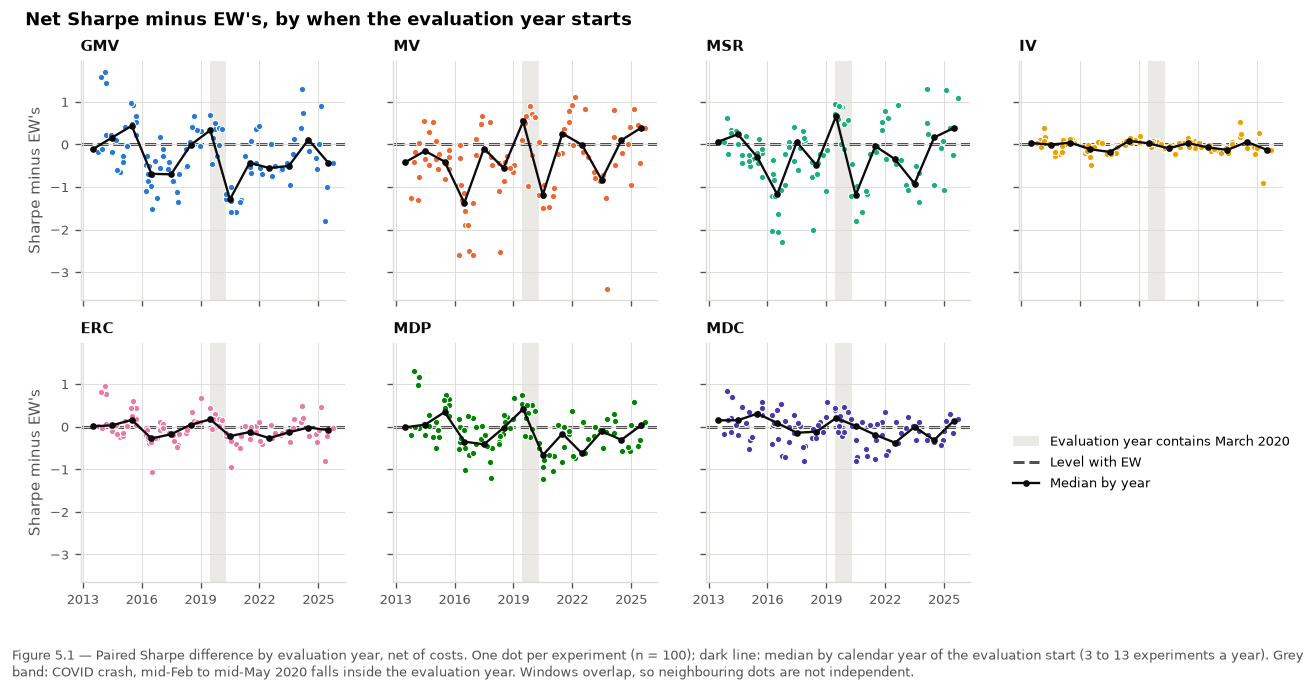

Median paired Sharpe difference by evaluation-start year:


strategy,n,GMV,MV,MSR,IV,ERC,MDP,MDC
evaluation_start,,,,,,,,
2013,3,-0.12,-0.42,0.06,0.03,0.01,-0.01,0.15
2014,8,0.16,-0.16,0.23,-0.01,0.03,0.04,0.15
2015,10,0.44,-0.41,-0.31,0.04,0.16,0.34,0.31
2016,13,-0.69,-1.38,-1.17,-0.11,-0.28,-0.35,0.09
2017,9,-0.70,-0.10,0.05,-0.18,-0.18,-0.42,-0.14
2018,9,-0.02,-0.56,-0.49,0.08,0.04,-0.03,-0.12
2019,10,0.33,0.54,0.66,0.02,0.17,0.41,0.20
2020,7,-1.29,-1.18,-1.19,-0.10,-0.22,-0.67,0.02
2021,9,-0.43,0.25,-0.04,0.03,-0.13,-0.17,-0.19


In [3]:
crisis = rb.crisis_exposure(experiments)
eval_start = experiments["evaluation_start"]
crash_starts = eval_start[crisis == "In evaluation year"]

fig, axes = viz.paired_by_date(d_sharpe, eval_start, shade=(crash_starts.min(), crash_starts.max()),
                               shade_label="Evaluation year contains March 2020")
fig.suptitle("Net Sharpe minus EW's, by when the evaluation year starts", x=0.01, ha="left",
             fontsize=11, fontweight="bold", y=1.02)
viz.caption(axes[1, 0], f"Figure 5.1 — Paired Sharpe difference by evaluation year, net of costs. One dot per "
                        f"experiment (n = {len(d_sharpe)}); dark line: median by calendar year of the evaluation start "
                        f"(3 to 13 experiments a year). Grey band: {STRESS_LABEL} falls inside the evaluation year. "
                        "Windows overlap, so neighbouring dots are not independent.")
plt.show()

by_year = d_sharpe.groupby(eval_start.dt.year).median()
by_year.insert(0, "n", eval_start.dt.year.value_counts().sort_index())
print("Median paired Sharpe difference by evaluation-start year:")
display(fmt.style(by_year, {"n": fmt.count, **{s: (lambda v: fmt.number(v, 2)) for s in d_sharpe.columns}}))

**No strategy's standing against EW drifts over time.** IV, ERC and MDC have yearly medians within
about 0.3 of zero from 2013 to 2025, with no trend: no stretch of years in which they reliably beat EW
or lose to it. **What varies is the year, and it tends to move the optimisers together.** Evaluation
years starting in 2016 and 2020 are bad for every strategy except MDC, and those starting in 2019,
which contain the crash, are good for all seven. GMV, MV and MSR swing most, which matches their
larger dispersion in Table 4.3. F3 picks up the crash directly.

---

## F3 — Crisis exposure

Experiments are grouped by where the crash (`stylised.STRESS_WINDOW`, mid-February to mid-May 2020) falls: in the
evaluation year, in the estimation period only, or neither. A one-session overlap counts, and the
evaluation year takes precedence.

In [4]:
pair_corr = rb.max_pair_correlation(prices, experiments)
pair = pd.Series(pd.Categorical(
    np.where(pair_corr > rb.COLLINEAR_THRESHOLD, f"Holds a pair > {rb.COLLINEAR_THRESHOLD}", "No such pair"),
    categories=[f"Holds a pair > {rb.COLLINEAR_THRESHOLD}", "No such pair"]), index=experiments.index)

long = rb.split_table(results, {"Crisis (March 2020)": crisis, "Near-collinear pair": pair})

def wide(measure):
    # One row per group, one column per strategy, in Table 5.2's row order.
    out = long[measure].unstack("strategy")[d_sharpe.columns]
    out.insert(0, "n", long["n"].groupby(level=["split", "group"]).first())
    return out.reindex(long.index.droplevel("strategy").unique())

period_rows = ["All experiments", "Crisis (March 2020)"]
for measure, rule in [("Beats EW (Sharpe) %", PCT(0)), ("Median Δ Sharpe", lambda v: fmt.number(v, 2)),
                      ("Lower vol %", PCT(0))]:
    print(f"{measure}, by crisis exposure:")
    t = wide(measure).loc[period_rows]
    display(fmt.style(t, {"n": fmt.count, **{s: rule for s in d_sharpe.columns}}))

Beats EW (Sharpe) %, by crisis exposure:


strategy                                         n GMV  MV MSR  IV ERC MDP MDC
split               group                                                     
All experiments     All                        100  36  32  35  45  41  38  53
Crisis (March 2020) In evaluation year          12  58  75  75  58  67  58  75
                    In estimation period only   15  20  40  27  47  20  13  33
                    Neither                     73  36  23  30  42  41  40  53

Median Δ Sharpe, by crisis exposure:


strategy                                         n    GMV     MV    MSR     IV    ERC    MDP    MDC
split               group                                                                          
All experiments     All                        100  -0.27  -0.33  -0.25  -0.01  -0.07  -0.12   0.01
Crisis (March 2020) In evaluation year          12   0.24   0.54   0.59   0.01   0.15   0.26   0.16
                    In estimation period only   15  -0.68  -0.20  -0.22  -0.04  -0.22  -0.69  -0.32
                    Neither                     73  -0.27  -0.44  -0.35  -0.02  -0.07  -0.08   0.01

Lower vol %, by crisis exposure:


strategy                                         n  GMV MV MSR   IV  ERC  MDP MDC
split               group                                                        
All experiments     All                        100   96  0  18  100   98   90  72
Crisis (March 2020) In evaluation year          12  100  0  58  100  100  100  92
                    In estimation period only   15   87  0   0  100   87   80  67
                    Neither                     73   97  0  15  100  100   90  70

**The crash helps the optimisers when it falls in the evaluation year, and hurts them when it falls only
in the estimation period.**

- **Crash in the evaluation year (12 experiments):** every strategy beats EW in more than half of them,
  and ERC in two-thirds. A defensive tilt pays when the crash happens inside the year being scored.
- **Crash in the estimation period only (15):** the reverse. ERC beats EW in a fifth of these, MDP in
  under a sixth, and GMV in a fifth. The estimates feeding these portfolios are dominated by crash-era
  volatilities and correlations, so the weights are fitted to a regime that has already passed. This
  matches §9's finding that crash windows distort the covariance estimate.
- **Neither (73):** close to the full-sample figures in Table 4.5.

**ERC's risk reduction does not depend on the period.** It has lower volatility than EW in 87–100% of
experiments in every group (third table). What depends on the period is the Sharpe comparison, and
mostly through where the crash falls.

---

## F4 — Asset subset

Two cuts. First, whether the subset holds a **near-collinear pair**: two assets whose correlation over
the trailing year that ends the estimation period exceeds 0.85, the threshold notebooks 03 and 06 use.
Second, **each asset in turn**: experiments that hold it against those that don't.

In [5]:
for measure, rule in [("Beats EW (Sharpe) %", PCT(0)), ("Median Δ Sharpe", lambda v: fmt.number(v, 2)),
                      ("Lower vol %", PCT(0))]:
    print(f"{measure}, by near-collinear pair:")
    t = wide(measure).loc[["All experiments", "Near-collinear pair"]]
    display(fmt.style(t, {"n": fmt.count, **{s: rule for s in d_sharpe.columns}}))

print("Pairs are not spread evenly across periods. Experiments by pair and crisis exposure:")
display(pd.crosstab(pair.rename("pair"), crisis.rename("crisis")))
print("... and by evaluation-start year:")
display(pd.crosstab(pair.rename("pair"), eval_start.dt.year.rename("evaluation start")))

Beats EW (Sharpe) %, by near-collinear pair:


strategy                                   n GMV  MV MSR  IV ERC MDP MDC
split               group                                               
All experiments     All                  100  36  32  35  45  41  38  53
Near-collinear pair Holds a pair > 0.85   24  21  17  12  38  25  29  54
                    No such pair          76  41  37  42  47  46  41  53

Median Δ Sharpe, by near-collinear pair:


strategy                                   n    GMV     MV    MSR     IV    ERC    MDP   MDC
split               group                                                                   
All experiments     All                  100  -0.27  -0.33  -0.25  -0.01  -0.07  -0.12  0.01
Near-collinear pair Holds a pair > 0.85   24  -0.84  -1.16  -1.03  -0.06  -0.22  -0.46  0.04
                    No such pair          76  -0.17  -0.24  -0.16  -0.01  -0.02  -0.06  0.01

Lower vol %, by near-collinear pair:


strategy                                   n GMV MV MSR   IV  ERC MDP MDC
split               group                                                
All experiments     All                  100  96  0  18  100   98  90  72
Near-collinear pair Holds a pair > 0.85   24  88  0   8  100   92  75  62
                    No such pair          76  99  0  21  100  100  95  75

Pairs are not spread evenly across periods. Experiments by pair and crisis exposure:


crisis,In evaluation year,In estimation period only,Neither
pair,,,
Holds a pair > 0.85,3,7,14
No such pair,9,8,59


... and by evaluation-start year:


evaluation start,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
pair,,,,,,,,,,,,,
Holds a pair > 0.85,0,0,3,8,1,1,1,6,2,1,0,0,1
No such pair,3,8,7,5,8,8,9,1,7,4,6,6,4


In [6]:
# Separate the pair from the period: compare within the crash-free experiments only.
calm = crisis == "Neither"
rows = {}
for g in pair.cat.categories:
    m = calm & (pair == g)
    rows[(g, "Median Δ Sharpe")] = d_sharpe[m].median()
    rows[(g, "Beats EW %")] = (d_sharpe[m] > 0).mean() * 100
within = pd.DataFrame(rows).T
within.insert(0, "n", [int((calm & (pair == g)).sum()) for g, _ in within.index])
print("Crash-free experiments only (crisis = Neither), by near-collinear pair:")
display(fmt.style(within, {"n": fmt.count, **{s: (lambda v: fmt.number(v, 2)) for s in d_sharpe.columns}}))

Crash-free experiments only (crisis = Neither), by near-collinear pair:


strategy                              n    GMV     MV    MSR     IV    ERC    MDP    MDC
Holds a pair > 0.85 Median Δ Sharpe  14  -0.41  -1.22  -0.86  -0.00  -0.05   0.02   0.11
                    Beats EW %       14  35.71   7.14   7.14  50.00  35.71  50.00  71.43
No such pair        Median Δ Sharpe  59  -0.19  -0.42  -0.26  -0.02  -0.08  -0.09  -0.02
                    Beats EW %       59  35.59  27.12  35.59  40.68  42.37  37.29  49.15

**A near-collinear pair hurts MV and MSR; for the risk-based strategies the apparent effect is the
period.** Across all experiments, subsets with a pair look worse for every optimiser except MDC. But
the pairs cluster in particular periods (crosstabs above): 15 of the 24 fall either in windows whose
estimation period holds the crash or in evaluation years starting in 2016, both bad for the optimisers
in F2–F3. Within the crash-free experiments only (14 with a pair, 59 without), IV, ERC, MDP and MDC
do about as well with a pair as without, GMV somewhat worse, and MV and MSR still much worse. A
plausible reason: two near-identical assets with different trailing means invite a mean-based
optimiser to load on one of them. Notebook 06 found that the pairs do not raise turnover, so any harm
comes through the weights, not through trading costs.

### Figure 5.2 — paired results by asset held

Each cell: the share of experiments in which the strategy beats EW on Sharpe when the subset **holds**
the asset, minus the share when it **does not**, in percentage points. Each asset is held in about 40
of the 100 experiments, by the two-per-sector draw.

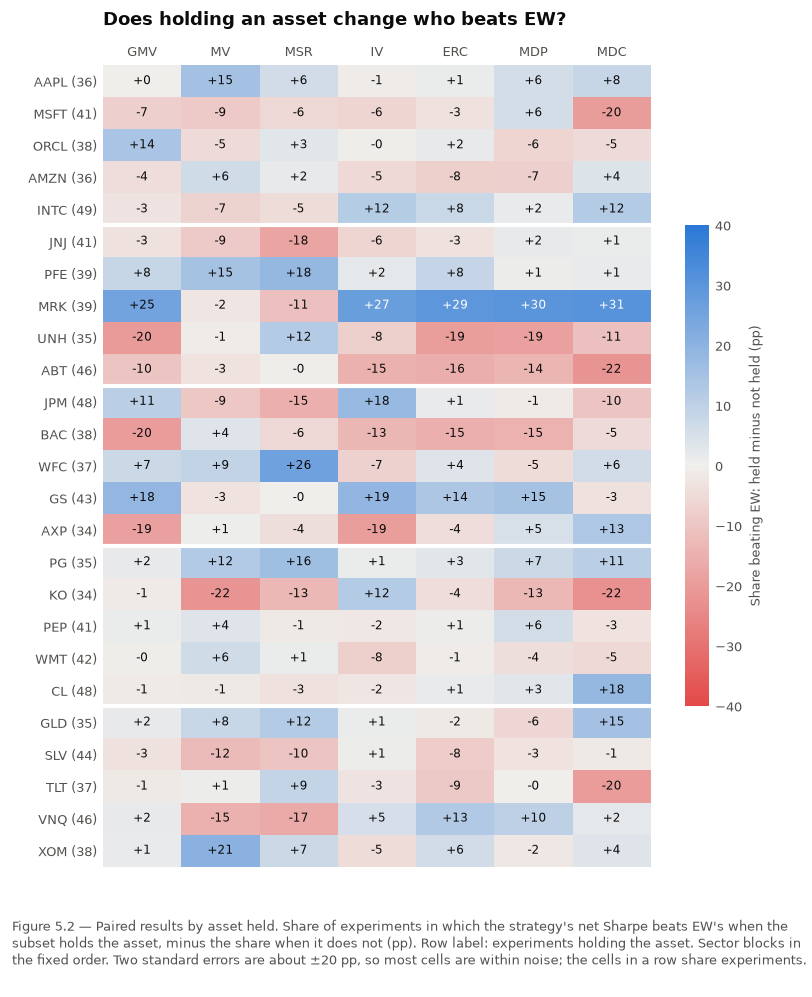

Cells beyond two standard errors: 12 of 175 (about 9 expected by chance if nothing mattered).
Two-SE yardstick, range across cells: ±19 to ±21 pp.
ERC: share with lower volatility than EW, held minus not held, ranges -5 to +3 pp across the 25 assets.
Largest Sharpe effects per strategy (pp):


,GMV,MV,MSR,IV,ERC,MDP,MDC
0,MRK +25,KO -22,WFC +26,MRK +27,MRK +29,MRK +30,MRK +31
1,UNH -20,XOM +21,PFE +18,AXP -19,UNH -19,UNH -19,KO -22
2,BAC -20,AAPL +15,JNJ -18,GS +19,ABT -16,GS +15,ABT -22


In [7]:
effect, n_held = rb.asset_effect(results, experiments)

fig, ax = plt.subplots(figsize=(6.6, 7.4))
viz.asset_effect_heatmap(effect, n_held, ax=ax)
ax.set_title("Does holding an asset change who beats EW?", pad=24)
fig.tight_layout()
# Noise yardstick: two standard errors of a difference in proportions at ~40 vs ~60 experiments.
p = (d_sharpe > 0).mean()
se2 = (2 * np.sqrt(np.outer(1 / n_held, p * (1 - p)) + np.outer(1 / (len(d_sharpe) - n_held), p * (1 - p))) * 100)
se2 = pd.DataFrame(se2, index=n_held.index, columns=p.index)
viz.caption(ax, f"Figure 5.2 — Paired results by asset held. Share of experiments in which the strategy's net Sharpe "
                f"beats EW's when the subset holds the asset, minus the share when it does not (pp). Row label: "
                f"experiments holding the asset. Sector blocks in the fixed order. Two standard errors are about "
                f"±{se2.median().median():.0f} pp, so most cells are within noise; the cells in a row share experiments.")
plt.show()

beyond = (effect.abs() > se2.reindex(effect.index)).to_numpy()
print(f"Cells beyond two standard errors: {beyond.sum()} of {beyond.size} "
      f"(about {0.05 * beyond.size:.0f} expected by chance if nothing mattered).")
print(f"Two-SE yardstick, range across cells: ±{se2.min().min():.0f} to ±{se2.max().max():.0f} pp.")

vol_effect = pd.DataFrame({a: ((d_vol < 0)[h].mean() - (d_vol < 0)[~h].mean()) * 100
                           for a, h in rb.holdings(experiments).items()}).T
print(f"{RECOMMENDED}: share with lower volatility than EW, held minus not held, ranges "
      f"{vol_effect[RECOMMENDED].min():+.0f} to {vol_effect[RECOMMENDED].max():+.0f} pp across the 25 assets.")
print("Largest Sharpe effects per strategy (pp):")
display(pd.DataFrame({s: effect[s].abs().nlargest(3).index.map(lambda a: f"{a} {effect.loc[a, s]:+.0f}")
                      for s in effect.columns}))

**No single asset decides the result.** The number of cells beyond two standard errors is close to
what chance alone would give (printed above), and the cells in a row are not independent: they share
the same experiments. The one pattern that repeats across strategies is in **healthcare**: subsets
holding `MRK` favour the risk-based group, and subsets holding `UNH` or `ABT` work against it. This
is a pattern in which healthcare name was drawn, not evidence about any one stock, and it is
reported, not explained. **ERC's lower volatility does not depend on which assets are drawn**: across
all 25 assets, holding one moves the share by at most a few points (printed above).

---

## Table 5.2 — sensitivity to period and subset

The main-report table: the share of experiments in which each strategy beats EW on net Sharpe, for
every group of F3 and F4. Appendix Table A5.1 adds the median difference and the share with lower
volatility.

In [8]:
table_5_2 = wide("Beats EW (Sharpe) %")
print("Table 5.2 - Sensitivity to period and subset. Share of experiments in which the strategy's net Sharpe "
      "beats EW's in the same experiment (%), by group. Groups are small; differences of 10-20 points can be noise. "
      f"Crisis: {STRESS_LABEL}. Pair: two assets correlated above {rb.COLLINEAR_THRESHOLD} over the trailing "
      "year that ends the estimation period.")
display(fmt.style(table_5_2, {"n": fmt.count, **{s: PCT(0) for s in d_sharpe.columns}}))

Table 5.2 - Sensitivity to period and subset. Share of experiments in which the strategy's net Sharpe beats EW's in the same experiment (%), by group. Groups are small; differences of 10-20 points can be noise. Crisis: COVID crash, mid-Feb to mid-May 2020. Pair: two assets correlated above 0.85 over the trailing year that ends the estimation period.


strategy                                         n GMV  MV MSR  IV ERC MDP MDC
split               group                                                     
All experiments     All                        100  36  32  35  45  41  38  53
Crisis (March 2020) In evaluation year          12  58  75  75  58  67  58  75
                    In estimation period only   15  20  40  27  47  20  13  33
                    Neither                     73  36  23  30  42  41  40  53
Near-collinear pair Holds a pair > 0.85         24  21  17  12  38  25  29  54
                    No such pair                76  41  37  42  47  46  41  53

In [9]:
table_a5_1 = long.drop(columns="Beats EW (Sharpe) %")
print("Table A5.1 - Table 5.2's groups, median paired Sharpe difference with EW and share of experiments with "
      "lower volatility than EW (%). Net of costs.")
display(fmt.style(table_a5_1, {"n": fmt.count, "Median Δ Sharpe": lambda v: fmt.number(v, 2),
                               "Lower vol %": PCT(0)}))

Table A5.1 - Table 5.2's groups, median paired Sharpe difference with EW and share of experiments with lower volatility than EW (%). Net of costs.


n Median Δ Sharpe Lower vol %
split               group                     strategy                                 
All experiments     All                       GMV       100           -0.27          96
                                              MV        100           -0.33           0
                                              MSR       100           -0.25          18
                                              IV        100           -0.01         100
                                              ERC       100           -0.07          98
                                              MDP       100           -0.12          90
                                              MDC       100            0.01          72
Crisis (March 2020) In evaluation year        GMV        12            0.24         100
                                              MV         12            0.54           0
                                              MSR        12            0.59          58
                                              IV         12            0.01         100
                                              ERC        12            0.15         100
                                              MDP        12            0.26         100
                                              MDC        12            0.16          92
                    In estimation period only GMV        15           -0.68          87
                                              MV         15           -0.20           0
                                              MSR        15           -0.22           0
                                              IV         15           -0.04         100
                                              ERC        15           -0.22          87
                                              MDP        15           -0.69          80
                                              MDC        15           -0.32          67
                    Neither                   GMV        73           -0.27          97
                                              MV         73           -0.44           0
                                              MSR        73           -0.35          15
                                              IV         73           -0.02         100
                                              ERC        73           -0.07         100
                                              MDP        73           -0.08          90
                                              MDC        73            0.01          70
Near-collinear pair Holds a pair > 0.85       GMV        24           -0.84          88
                                              MV         24           -1.16           0
                                              MSR        24           -1.03           8
                                              IV         24           -0.06         100
                                              ERC        24           -0.22          92
                                              MDP        24           -0.46          75
                                              MDC        24            0.04          62
                    No such pair              GMV        76           -0.17          99
                                              MV         76           -0.24           0
                                              MSR        76           -0.16          21
                                              IV         76           -0.01         100
                                              ERC        76           -0.02         100
                                              MDP        76           -0.06          95
                                              MDC        76            0.01          75

---

## Do the conclusions depend on period or subset?

**Draft sentence for the report.** ERC's case rests on lower risk than EW at about the same
risk-adjusted return. **The lower risk holds in every period and every subset split.** The Sharpe
comparison with EW **does depend on the period**, mainly on where the March 2020 crash falls: the
optimisers gain on EW when the crash is in the evaluation year and lose when it sits only in the
estimation data. **It depends little on the subset**, except that MV and MSR do markedly worse when
the subset holds a near-collinear pair. These splits are descriptive, and period and subset are not
fully separable.

---

## Done-when checks (F2–F4)

In [10]:
checks = []
checks.append(("Figure 5.1 covers every experiment and the seven strategies other than EW",
               d_sharpe.shape == (cfg.N_EXPERIMENTS, len(cfg.STRATEGY_ORDER) - 1)))
checks.append(("Crisis groups partition the 100 experiments",
               crisis.notna().all() and crisis.value_counts().sum() == cfg.N_EXPERIMENTS))
checks.append(("Pair groups partition the 100 experiments", pair.value_counts().sum() == cfg.N_EXPERIMENTS))
checks.append(("Table 5.2's 'All experiments' row matches Table 4.5's win rate",
               np.allclose(table_5_2.loc[("All experiments", "All"), list(d_sharpe.columns)].astype(float),
                           pf.paired_table(results)["Beats EW (Sharpe) %"])))
checks.append(("Every asset is held in some experiments and missing from others",
               bool(((n_held > 0) & (n_held < cfg.N_EXPERIMENTS)).all())))
for label, ok in checks:
    print(f"[{'PASS' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks), "workstream F (F2-F4) exit criteria not met"

[PASS] Figure 5.1 covers every experiment and the seven strategies other than EW
[PASS] Crisis groups partition the 100 experiments
[PASS] Pair groups partition the 100 experiments
[PASS] Table 5.2's 'All experiments' row matches Table 4.5's win rate
[PASS] Every asset is held in some experiments and missing from others


---

## Handoff

| Output | Report |
| --- | --- |
| Figure 5.1, Table 5.2, Figure 5.2 | Section 6, *Robustness checks and limitations* |
| Table A5.1 | Appendix |
| The draft sentence above | Section 6, and the reconsideration conditions in section 7 |

Still to do in this notebook: F1 (Table 5.1, from `results["net_2x"]`), F5 (Table 5.3, from
`grid.runs`) and F6 (the limitations).